# Predicting Airline Satisfaction

In [1]:
# import required libbraries
import numpy as  np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

print("Libraries imported successfully...Bliss")

Libraries imported successfully...Bliss


In [2]:
sample_submission = "/kaggle/input/competitions/playground-series-s6e10/sample_submission.csv"
test = "/kaggle/input/competitions/playground-series-s6e10/test.csv"
train = "/kaggle/input/competitions/playground-series-s6e10/train.csv"

df_sample = pd.read_csv(sample_submission)
df_test = pd.read_csv(test)
df_train = pd.read_csv(train)

print("Dataset loaded successfully")

Dataset loaded successfully


In [3]:
df_sample.head()

,id,satisfaction
0,699635,0.443573
1,699636,0.443573
2,699637,0.443573
3,699638,0.443573
4,699639,0.443573


In [4]:
df_test.head()

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,...,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class
0,699635,25,1197,4,4,4,2,3,4,3,...,5,2,1,3,0,0.0,Female,disloyal Customer,Business travel,Eco
1,699636,36,829,5,5,5,5,5,4,5,...,2,4,3,5,0,0.0,Male,Loyal Customer,Business travel,Eco
2,699637,45,472,4,5,5,5,4,4,4,...,3,1,3,4,0,0.0,Male,Loyal Customer,Business travel,Eco
3,699638,45,762,2,2,2,5,3,2,3,...,4,4,4,3,0,0.0,Female,disloyal Customer,Business travel,Business
4,699639,34,594,1,2,1,1,2,1,2,...,4,2,1,2,0,0.0,Male,Loyal Customer,Personal Travel,Eco Plus


In [5]:
df_train.head()

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,...,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
0,0,36,694,4,4,4,3,1,4,1,...,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
1,1,56,651,5,5,5,5,5,4,4,...,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,True
2,2,31,1371,3,4,2,5,3,3,3,...,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
3,3,10,1616,3,5,3,3,3,3,3,...,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,False
4,4,23,481,3,4,3,4,5,3,5,...,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,False


In [6]:
print(f"sample_submission Data Shape:")
print(f"Rows: {df_sample.shape[0]} | Columns: {df_sample.shape[1]}\n")

print(f"Test Data Shape:")
print(f"Rows: {df_test.shape[0]} | Columns: {df_test.shape[1]}\n")

print(f"Train Data Shape:")
print(f"Rows: {df_train.shape[0]} | Columns: {df_train.shape[1]}")

sample_submission Data Shape:
Rows: 299844 | Columns: 2

Test Data Shape:
Rows: 299844 | Columns: 22

Train Data Shape:
Rows: 699635 | Columns: 23


In [7]:
df_sample_list = df_sample.columns.tolist()
df_train_list = df_train.columns.tolist()
df_test_list = df_test.columns.tolist()

print("df_sample_list\n", df_sample_list, "\n")
print("df_train_list\n", df_train_list, "\n")
print("df_test_list\n", df_test_list)

df_sample_list
 ['id', 'satisfaction'] 

df_train_list
 ['id', 'Age', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes', 'Gender', 'Customer Type', 'Type of Travel', 'Class', 'satisfaction'] 

df_test_list
 ['id', 'Age', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes', 'Gender', 'Customer Type', 'Type of Travel', 'Class']


In [8]:
print(df_train["satisfaction"].value_counts())
print(df_train["satisfaction"].value_counts(normalize=True).mul(100).round(2))

satisfaction
False    389296
True     310339
Name: count, dtype: int64
satisfaction
False    55.64
True     44.36
Name: proportion, dtype: float64


In [9]:
## Missing values

dfs = {
    "Train" : df_train,
    "Test" : df_test
}

for name, df in dfs.items():
    print(f"Missing values in {name} Data")
    print(df.isnull().sum()[df.isnull().sum() > 0])
    print("-"*50)

Missing values in Train Data
Arrival Delay in Minutes    292
dtype: int64
--------------------------------------------------
Missing values in Test Data
Arrival Delay in Minutes    130
dtype: int64
--------------------------------------------------


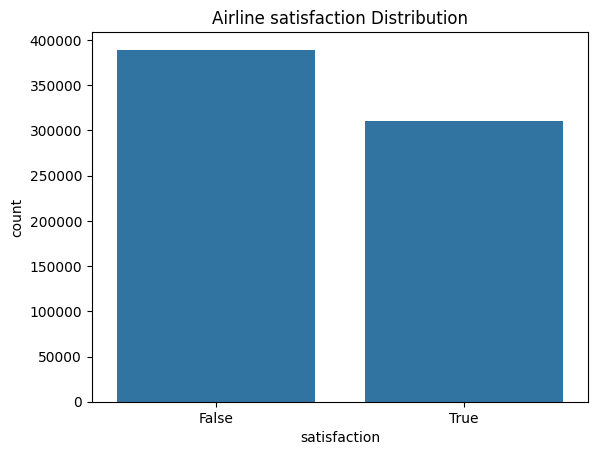

In [10]:
sns.countplot(data=df_train, x="satisfaction")
plt.title("Airline satisfaction Distribution")
plt.show()

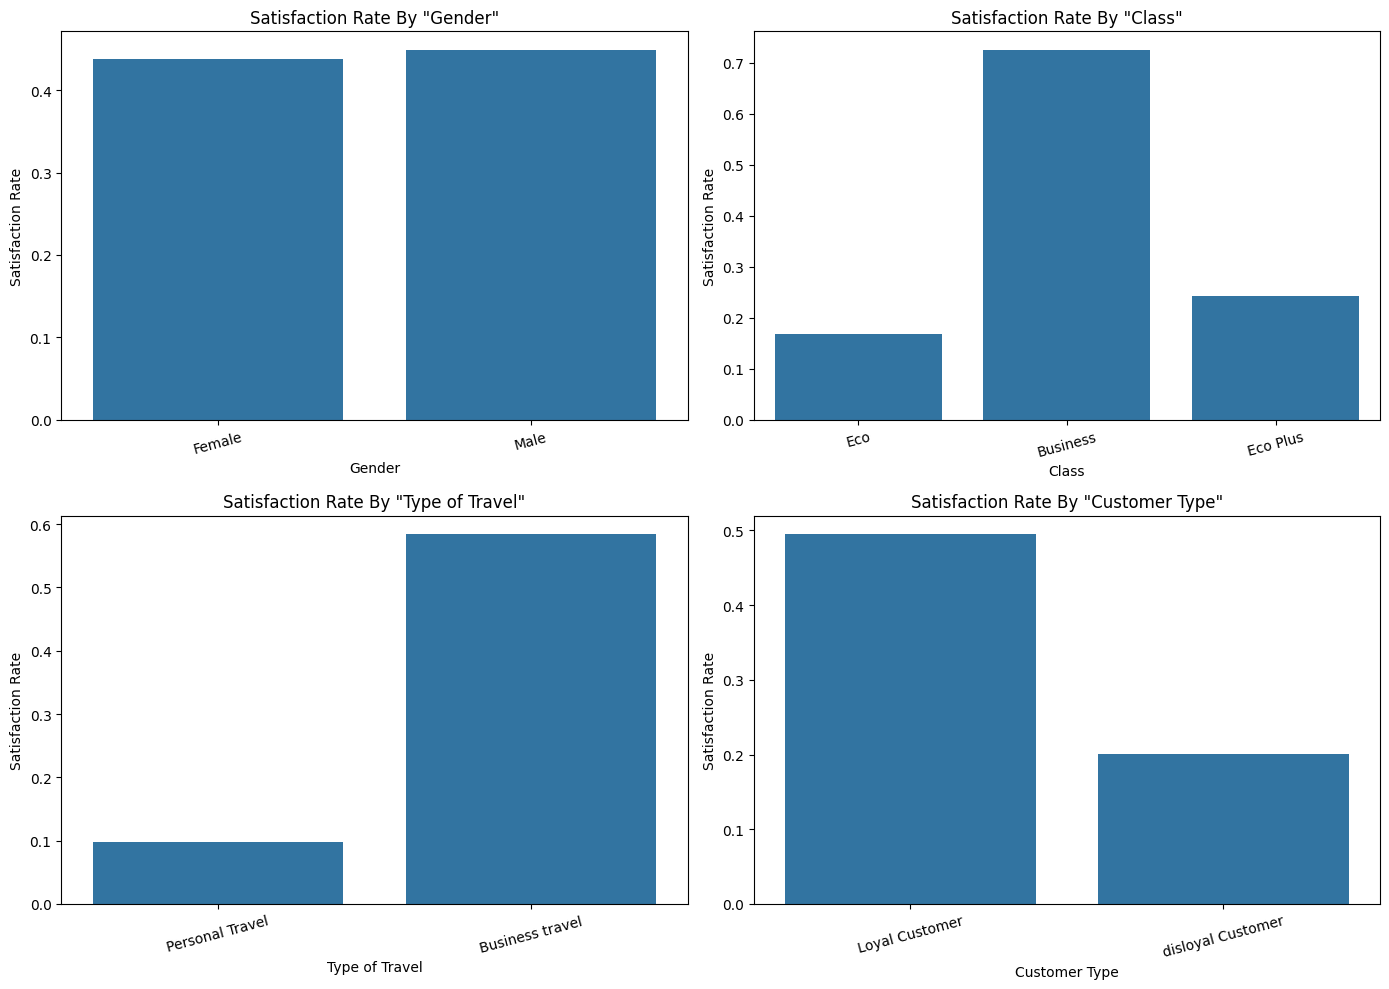

In [11]:
cat_cols = ["Gender", "Class", "Type of Travel", "Customer Type"]

# Create a 2x2 grid of subplots
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(14, 10))
axes = axes.flatten()  # Flatten to easily iterate through axes with a single loop

for i, col in enumerate(cat_cols):
    
    # Plot on the specific subplot axis
    sns.barplot(data=df_train, x=col, y="satisfaction", errorbar=None, ax=axes[i])
    axes[i].set_title(f"Satisfaction Rate By \"{col}\"")
    axes[i].set_ylabel("Satisfaction Rate")
    axes[i].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

## Analyze airline service rating

In [12]:
print("df_train_list\n", df_train_list, "\n")

df_train_list
 ['id', 'Age', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes', 'Gender', 'Customer Type', 'Type of Travel', 'Class', 'satisfaction'] 



In [13]:
service_feature = ["service", "comfort", "food", "drink", "cleanliness", "entertainment", "boarding", "wifi", "check-in", "checkin", "online booking", "leg room"]

ser_fest = []
print("Service-related columns:")
for col in df_train.columns:
    # check if any keyword in service_feature is a substring of the column name
    if any(feat in col.lower() for feat in service_feature):
        ser_fest.append(col)
        print(f"-{col}")

Service-related columns:
-Inflight wifi service
-Ease of Online booking
-Food and drink
-Online boarding
-Seat comfort
-Inflight entertainment
-On-board service
-Leg room service
-Checkin service
-Cleanliness


In [14]:
print(ser_fest)

['Inflight wifi service', 'Ease of Online booking', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Checkin service', 'Cleanliness']


In [15]:
comparison = df_train.groupby("satisfaction")[ser_fest].mean().T
print(comparison.round(2))

satisfaction            False  True 
Inflight wifi service    2.45   3.20
Ease of Online booking   2.59   3.10
Food and drink           3.01   3.58
Online boarding          2.72   4.17
Seat comfort             3.11   4.14
Inflight entertainment   2.95   4.09
On-board service         3.13   4.00
Leg room service         3.10   3.94
Checkin service          3.15   3.76
Cleanliness              2.99   3.87


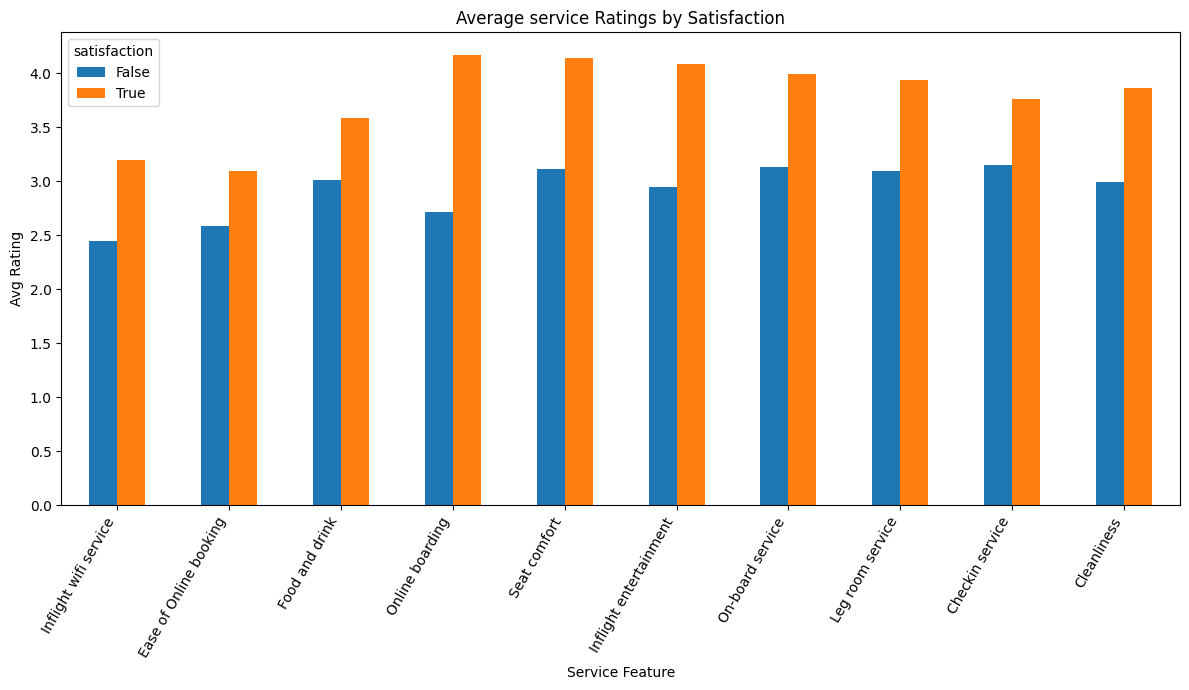

In [16]:
#Visualize the difference

comparison.plot(
    kind="bar",
    figsize=(12, 7)
)

plt.title("Average service Ratings by Satisfaction")
plt.ylabel("Avg Rating")
plt.xlabel("Service Feature")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()

## Analyze flight delayes

In [17]:
delay_feature = ["Departure Delay in Minutes",
                  "Arrival Delay in Minutes"
                  ]

delay_fest = []
print("Delay-related columns:")
for col in df_train.columns:
    # check if any keyword in delay_feature is a substring of the column name
    if any(feat.lower() in col.lower() for feat in delay_feature):
        delay_fest.append(col)
        print(f"-{col}")

Delay-related columns:
-Departure Delay in Minutes
-Arrival Delay in Minutes


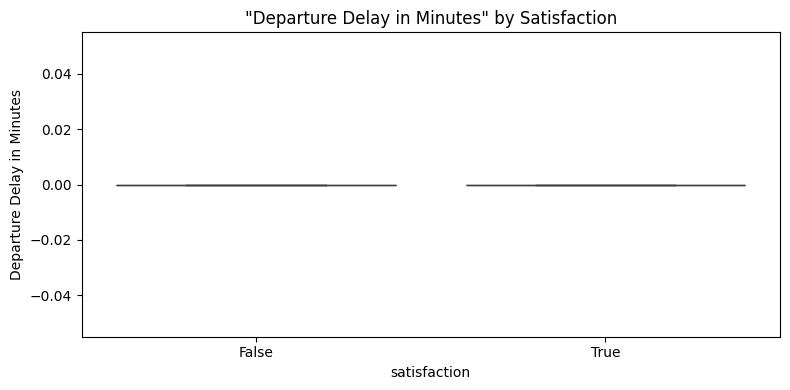

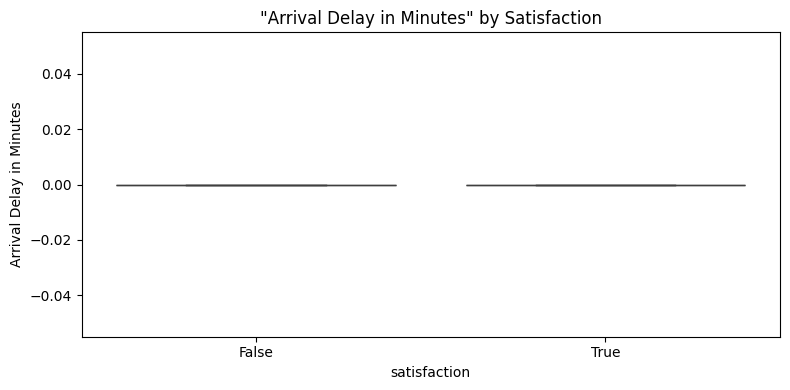

In [18]:
# Visualize the distribution

for col in delay_fest:
    plt.figure(figsize=(8, 4))

    sns.boxplot(
        data=df_train,
        x="satisfaction",
        y=col,
        showfliers=False
    )

    plt.title(f"\"{col}\" by Satisfaction")
    plt.tight_layout()
    plt.show()

## Analyze numerical feature

In [19]:
num_cols = df_train.select_dtypes(include="number").columns.tolist()

for col in num_cols:
    if col == "id":
        num_cols.remove(col)
print(num_cols)

['Age', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes']


In [20]:
display(df_train[num_cols].describe().drop("count").T.round(2))

,mean,std,min,25%,50%,75%,max
Age,39.00,13.80,7.0,27.0,40.0,50.0,85.0
Flight Distance,1353.78,954.42,67.0,631.0,954.0,1814.0,4983.0
Inflight wifi service,2.78,1.28,0.0,2.0,3.0,4.0,5.0
Departure/Arrival time convenient,3.16,1.48,0.0,2.0,3.0,4.0,5.0
Ease of Online booking,2.81,1.33,0.0,2.0,3.0,4.0,5.0
Gate location,3.01,1.25,0.0,2.0,3.0,4.0,5.0
Food and drink,3.27,1.30,0.0,2.0,3.0,4.0,5.0
Online boarding,3.36,1.29,0.0,2.0,4.0,4.0,5.0
Seat comfort,3.57,1.28,0.0,3.0,4.0,5.0,5.0
Inflight entertainment,3.45,1.31,0.0,2.0,4.0,5.0,5.0
